**Autores: Raul Matei Plohod y Daniel Navarro Puche**

# Optimizacion de controladores PID mediante algoritmos geneticos

EJERCICIO DE OPTIMIZACIÓN DE LAS GANANCIAS DEL CONTROLADOR PID.

Sobre el controlador PID desarrollado en la práctica anterior, desarrollar un algoritmo genético que sea capaz de optimizar el valor de las ganancias Kp, Ki y Kd, a fin de obener el controlador con mejor rendimiento posible.
Para ello, se debe:
- Definir el tamaño del cromosoma
- Definir la función de fitness
- La selección se realizará por torneo. Definir el valor de T
- Especificar el número de itaraciones para ajustar el controlador
- Definir el tamaño de la población


MODELO, CONTROLADOR PID E ÍNDICES DE RENDIMIENTO

In [35]:
import stat
class DCMotorSim:
    def __init__(self):
        self.R = 1.11  # Ohm
        self.L = 0.0002  # H
        self.J = 6.77E-6  # Kgm²
        self.fv = 1.66E-5  # Nm/(Rad/s)
        self.K = 0.0364  # Nm/A or V/(Rad/s)
        self.voltage = 0.0
        self.w = [0.0, 0.0]  # tk speed
        self.i = [0.0, 0.0]  # tk current

    def init(self):
        self.R = 1.11
        self.L = 0.0002
        self.J = 6.77E-6
        self.fv = 1.66E-5
        self.K = 0.0364
        self.voltage = 0.0
        self.w = [0.0, 0.0]
        self.i = [0.0, 0.0]

    def set_voltage(self, new_voltage):
        self.voltage = new_voltage
        # Saturation effect due to battery limits
        if self.voltage > 24.0:
            self.voltage = 24.0
        if self.voltage < -24.0:
            self.voltage = -24.


    def get_speed(self): 
        return self.w[0]

    def exec_cycle(self):
        # Motor behavior considering T = 0.0001s
        self.w[0] = self.w[1]
        self.i[0] = self.i[1]
        self.w[1] = 0.999755 * self.w[0] + 14.769238 * self.K * self.i[0]
        self.i[1] = 0.574072 * self.i[0] + 0.383719 * (self.voltage - self.K * self.w[1])
        

class Controller:
    def __init__(self):
        self.Kp = 0.0
        self.Ki = 0.0
        self.Kd = 0.0
        self.reference_speed = 0.0
        self.controller_t = 0.001
        self.motor_sim = DCMotorSim()
        self.motor_speed_anterior = 0
        self.previous_I = 0
        self.previous_D = 0
        self.proportions = []
        self.integrals = []
        self.derivatives = []
        self.registry = dict()  # For later gradient-based optimization
        
    def init(self, new_Kp: float, new_Ki: float, new_Kd: float):
        self.Kp = new_Kp
        self.Ki = new_Ki
        self.Kd = new_Kd
        
        # Reiniciar las variables de estado del PID
        self.motor_speed_anterior = 0.0
        self.previous_I = 0.0
        self.previous_D = 0.0
        self.proportions = []
        self.integrals = []
        self.derivatives = []

        # Inicializar el motor
        self.motor_sim.init()
        

    def set_reference(self, speed: float):
        self.reference_speed = speed

    def exec_controller_cycle(self, noisy: bool = True):
        # Compute control parameters
        motor_speed = DCMotorSim.get_speed(self.motor_sim)


        error = self.reference_speed - motor_speed
        error_anterior = self.reference_speed - self.motor_speed_anterior
        
        P = self.Kp * error
        self.proportions.append(error)
        I = self.previous_I + self.Ki * error * self.controller_t
        self.integrals.append(I / self.Ki if abs(self.Ki) > 1e-10 else error * self.controller_t)
        
        if not noisy and abs(self.Kd) > 1e-10:
            # Based on finite difference derivative approximation via Taylor expansion
            # but including the derivative since we are already saving it
            # f(x - h) = f(x) - h * f'(x) + h^2/2 * f''(x) - h^3/6 * f'''(x) + ...
            # f'(x-h) = f'(x) - h * f''(x) + h^2/2 * f'''(x) - h^3/6 * f''''(x) + ...
            
            # f(x) - f(x - h) = h * f'(x) - h^2/2 * f''(x) + h^3/6 * f'''(x) - ...
            # 2f(x) - 2f(x - h) - h * f'(x-h) = h * f'(x) - h^3/3 * f'''(x) + ...
            # Solving for f'(x): f'(x) = 2 * (f(x) - f(x - h)) / h - f'(x-h) + h^2/3 * f'''(x) - ...
            # Which in practice is: f'(x) = 2 * (f(x) - f(x - h)) / h - f'(x-h) + O(h^2) (for small enough h)
            D = 2 * (error - error_anterior) / self.controller_t - self.previous_D / self.Kd
            
            # However, noise can cause big errors in this approximation

        elif self.Kp == 0 or self.Kd == 0:
            D = 0
        else:
            Td = self.Kd / self.Kp
            N = 10  # Noise filter (normally between 8-20)
            h = self.controller_t
            
            denominator = Td + N * h
            term1 = Td / (Td + N * h) * self.previous_D
            term2 = self.Kd * N / denominator * (error - error_anterior)
            D = term1 + term2
            
        self.derivatives.append(D / self.Kd if abs(self.Kd) > 1e-10 else (error - error_anterior) / self.controller_t)
        
        # Prepare last error for next cycle       
        self.motor_speed_anterior = motor_speed

        # Prepare last I and D for next cycle
        self.previous_I = I
        self.previous_D = D
        
        # Compute controller output
        new_motor_voltage = P+I+D
        DCMotorSim.set_voltage(self.motor_sim, new_motor_voltage)
        DCMotorSim.exec_cycle(self.motor_sim)

        return motor_speed, new_motor_voltage
    
    def calculate_gradients(self):
        if not hasattr(self, 'proportions_mean'):
            self.proportions_mean = stat.mean(self.proportions)
            self.integrals_mean = stat.mean(self.integrals)
            self.derivatives_mean = stat.mean(self.derivatives)
        
        self.registry[tuple((self.Kp, self.Ki, self.Kd))] = (self.proportions_mean, self.integrals_mean, self.derivatives_mean)
        return self.proportions_mean, self.integrals_mean, self.derivatives_mean
    
    
from math import ceil
import numpy as np
import statistics as stat

class Performance:    
    def __init__(self):
        self.overshoot = 0.0
        self.decay_ratio = 0.0
        self.steady_state_error = 0.0
        self.time_to_settle = 0.0
        self.v = []
        self.ref_v = 0.0

    def init(self, velocidades: list[float], velocidad_de_referencia: float):
        self.overshoot = 0.0
        self.decay_ratio = 0.0
        self.steady_state_error = 0.0
        self.time_to_settle = 0.0
        self.v = velocidades
        self.ref_v = velocidad_de_referencia
        
    def get_crossings(self) -> list[int]:
        crossings = []
        for i in range(len(self.v)-1):
            if (self.v[i] - self.ref_v) * (self.v[i+1] - self.ref_v) < 0:  # Check for crossing
                crossings.append(i)
        return crossings
    
    def get_peaks(self) -> list[int]:
        peaks = []
        for i in range(1, len(self.v)-1):
            if self.v[i] > self.v[i-1] and self.v[i] > self.v[i+1]:
                peaks.append(i)
        return peaks
    
    def calculate_overshoot(self) -> float:
        initial_speed = self.v[0]
        overshoot_speed = max(self.v) if initial_speed < self.ref_v else min(self.v)
        A = overshoot_speed - self.ref_v
        B = initial_speed - self.ref_v
        if A * B < 0:  # Check if there is an overshoot in the opposite direction of the initial speed
            return - A / B
        else:
            return 0
    
    def calculate_decay_ratio(self, peaks: list[int] | None = None) -> float:
        # We can calculate it if there are at least 2 peaks
        peaks = self.get_peaks() if peaks is None else peaks
        if len(peaks) < 2:
            return 0
        
        c = self.v[-1]
        total = 1
        for i in range(len(peaks)-1):
            total *= abs(peaks[i+1] - c) / abs(peaks[i] - c)
            
        return total ** (1/(len(peaks)-1))  # Geometric mean of the ratios since it multiplicatively decay
    
    def calculate_time_to_settle(self, crosses: list[int] | None = None, peaks: list[int] | None = None) -> float:
        crosses = self.get_crossings() if crosses is None else crosses
        peaks = self.get_peaks() if peaks is None else peaks
        if getattr(self, 'decay_ratio', None) is None:
            self.decay_ratio = self.calculate_decay_ratio(peaks)
            
        if self.decay_ratio >= 1:  # No decay, so it doesn't settle
            return float('inf')

        band = 0.02 * self.ref_v  # 2% value reference
        sup_limit = self.ref_v + band
        inf_limit = self.ref_v - band
        if len(crosses) > 1:
            # Estimate it interpolating geometrically between peaks
            # f(x) = 1 / (d^(x/T)) * C + offset
            # (f(x) - offset) * d^(x/T) = C
            offset = self.v[-1]
            period = stat.mean(peaks)
            C = stat.mean((self.v[i] - offset) * self.decay_ratio ** (i / period) for i in peaks)
            
            # Now we cross it with the bands by solving for x in f(x)
            # C / (f(x) - offset) = d^(x/T)
            # log(C / (f(x) - offset)) / log(d) * T = x
            
            denominator_inf = - inf_limit - offset
            denominator_sup = sup_limit - offset
            x_inf = float('inf')
            if denominator_inf != 0 and C / denominator_inf > 0:
                x_inf = (np.log(C / denominator_inf) / np.log(self.decay_ratio)) * period
            
            x_sup = float('inf')
            if denominator_sup != 0 and C / denominator_sup > 0:
                x_sup = (np.log(C / denominator_sup) / np.log(self.decay_ratio)) * period
                
            time_to_settle = min(x_inf, x_sup)
            
        else:
            time_to_settle = len(self.v)
            for i in range(len(self.v))[::-1]:
                if self.v[i] > sup_limit or self.v[i] < inf_limit:
                    time_to_settle = i + 1
                    break
            
            if time_to_settle == len(self.v):  # Doesn't settle in time
                time_to_settle = float('inf')
        
        # If it's amplitud increases that means no settling
        return time_to_settle if time_to_settle > 0 else float('inf')
    
    def calculate_steady_state_error(self, time_to_settle: float | None = None) -> float:
        time_to_settle = self.calculate_time_to_settle() if time_to_settle is None else time_to_settle
        
        # Weird comparison because it might be infinite or just barely bigger
        if time_to_settle > len(self.v) or ceil(time_to_settle) >= len(self.v):
            return float('inf')
        
        return stat.mean(abs(self.v[i] - self.ref_v) for i in range(ceil(time_to_settle), len(self.v)))
    
        
    def calcula_indexes(self):
        crosses = self.get_crossings()
        peaks = self.get_peaks()
   
        self.overshoot = self.calculate_overshoot()
        self.decay_ratio = self.calculate_decay_ratio(peaks)
        self.time_to_settle = self.calculate_time_to_settle(crosses, peaks)
        self.steady_state_error = self.calculate_steady_state_error(self.time_to_settle)

        return self.overshoot, self.decay_ratio, self.steady_state_error, self.time_to_settle


## Algoritmo Genético

ALGORITMO GENÉTICO --> El mismo desarrollado en la práctica de Sistemas Inteligentes. Solo cambia el fitness


In [36]:
from genetic_metaheuristics.metaheuristics.reals import RealsMetaheuristicGeneticOptimizer
from numpy import ndarray

class PIDGeneticOptimizer(RealsMetaheuristicGeneticOptimizer):
            
    def set_controller(self, controller: Controller):
        self.controller = controller
        
    def set_performance(self, performance: Performance):
        self.performance = performance

    def calculate_gene_fitness(self, gene: ndarray) -> float:
        Kp, Ki, Kd = gene
        self.controller.init(Kp, Ki, Kd)
        self.controller.set_reference(50.0)
        
        velocidades = []
        for _ in range(320):
            motor_speed, new_motor_voltage = self.controller.exec_controller_cycle()
            velocidades.append(motor_speed)
        
        # Update registry (for later gradient-based optimization)
        self.controller.calculate_gradients()
        
        # Calculate performance indices
        self.performance.init(velocidades, self.controller.reference_speed)
        overshoot, decay_ratio, steady_state_error, time_to_settle = self.performance.calcula_indexes()
        
        # Return a fitness value based on the performance indices (e.g., minimize overshoot and settling time)
        time_to_settle = time_to_settle if time_to_settle != float('inf') else 1000
        steady_state_error = steady_state_error if steady_state_error != float('inf') else 1000
        fitness = overshoot + decay_ratio + steady_state_error + time_to_settle
        
        return fitness

Dibujar el resultado de la optimización mediante el algoritmo genético. No tocar

In [37]:
from matplotlib import pyplot as plt

class dibujacontrol:
    

    def dibujar (self, Kp, Ki, Kd):
        
        fig, ax = plt.subplots()
        fig, ax2 = plt.subplots()
        P = Performance()  
        
        # Crear una instancia del controlador
        controller = Controller()

        
        velocidad=[]
        ut=[]
        coordenadax=[]

        Velocidad_de_referencia = 50.0
        
        # Inicializar el controlador con los valores de ganancia
        controller.init(Kp, Ki, Kd)

        # Establecer la velocidad de referencia
        controller.set_reference(Velocidad_de_referencia)

        # Ejecutar 320 ciclos del controlador
        for ite in range(320):
            x,y = controller.exec_controller_cycle()
            velocidad.append(x)
            ut.append(y)
            coordenadax.append(ite)
        
        ax.set_title("Salida del Sistema")  
        ax.plot(coordenadax, velocidad, linewidth=2.0)
        ax.grid(axis='x', color='0.95')
        ax.grid(axis='y', color='0.95')
        ax2.set_title("Señal de control")
        ax2.plot(coordenadax, ut, linewidth=2.0)
        ax2.grid(axis='x', color='0.95')
        ax2.grid(axis='y', color='0.95')

        P.init(velocidad, Velocidad_de_referencia)
        o, d, Ess, Ts = P.calcula_indexes()
        print("Overshoot: ",o)
        print("d: ",d)
        print("Ess: ",Ess)
        print("Ts:", Ts)

In [38]:
pid_genetic_optimizer = PIDGeneticOptimizer(
    gene_length=3,
    cross_prob=0.6,
    mut_prob=0.1,
    tournament_participants=2,
    operator='gaussian',
    gaussian_mutation_scale=3,
    maximize=False,
    seed=None,
    on_keyboard_interrupt='raise',
    max_workers=None
)

pid_genetic_optimizer.set_controller(Controller())
pid_genetic_optimizer.set_performance(Performance())

In [39]:
population = pid_genetic_optimizer.create(N=100)
population = pid_genetic_optimizer.evolve(population, num_generations=200) # type: ignore

Generaciones:  12%|█▎        | 25/200 [00:01<00:10, 16.02it/s]/tmp/ipykernel_21290/3618762648.py:118: RuntimeWarning: overflow encountered in scalar divide
  self.derivatives.append(D / self.Kd if abs(self.Kd) > 1e-10 else (error - error_anterior) / self.controller_t)
/tmp/ipykernel_21290/3618762648.py:114: RuntimeWarning: overflow encountered in scalar multiply
  term1 = Td / (Td + N * h) * self.previous_D
Generaciones: 100%|██████████| 200/200 [00:16<00:00, 12.48it/s]


Fitness óptimo: 157.363
Mejor individuo [ 0.01149693  3.17253586 -1.09705095]


Llamada al algoritmo genético (tarda un poquito, en función de el número de generaciones programadas)

Mejor cromosoma: [ 0.01149693  3.17253586 -1.09705095]
Overshoot:  0
d:  0
Ess:  0.36277199727266446
Ts: 157


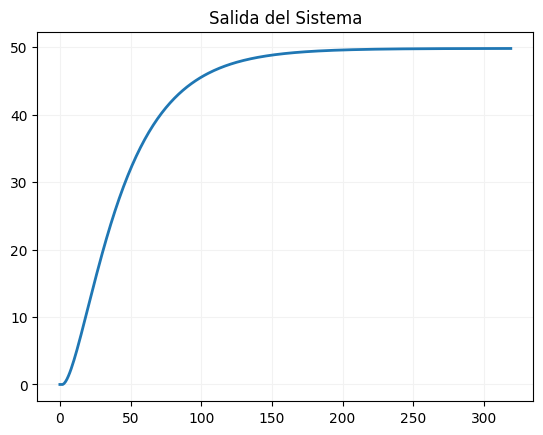

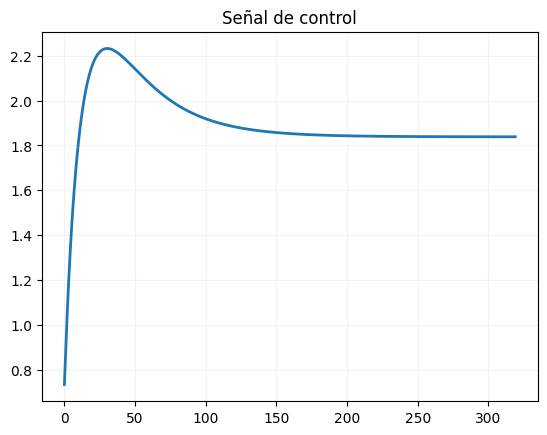

In [40]:
best_individual = population[0]
gene, fitness = best_individual
print("Mejor cromosoma:", gene)

DC = dibujacontrol()
DC.dibujar(gene[0],gene[1], gene[2])

## Operador basado en gradiente

In [41]:
from typing import Callable
from genetic_metaheuristics.typing import Gene, Individual
from genetic_metaheuristics.operators.reals import RealsOperator
class PIDGradientOperator(RealsOperator):
    def __init__(
        self,
        gene_fitness_func: Callable[[np.ndarray], float],
        optimizer_registry: dict,
        mutation_scale: float = 0.1,
    ):
        self.mutation_scale = mutation_scale
        self.gene_fitness_func = gene_fitness_func
        self.optimizer_registry = optimizer_registry
        
    def __call__(
        self,
        individual: Individual[np.ndarray],
    ) -> Individual[np.ndarray]:
        gene, fitness = individual
        gradient = self.optimizer_registry.get(tuple(gene), (0.0, 0.0, 0.0))
        
        # Perform mutation randomly along the gradient direction
        mutation = np.random.normal(loc=0.0, scale=self.mutation_scale, size=gene.shape)
        mutated_gene = gene + mutation * np.array(gradient)
        new_fitness = self.gene_fitness_func(mutated_gene)
        new_individual = (mutated_gene, new_fitness)
        return new_individual
    


In [45]:
pid_genetic_gradient_optimizer = PIDGeneticOptimizer(
    gene_length=3,
    cross_prob=0.1,
    mut_prob=0.9,
    tournament_participants=2,
    operator='gaussian',
    gaussian_mutation_scale=3,
    maximize=False,
    seed=None,
    on_keyboard_interrupt='raise',
    max_workers=None
)

pid_genetic_gradient_optimizer.set_controller(Controller())
pid_genetic_gradient_optimizer.set_performance(Performance())

gradient_operator = PIDGradientOperator(
    gene_fitness_func=pid_genetic_gradient_optimizer.calculate_gene_fitness,
    optimizer_registry=pid_genetic_gradient_optimizer.controller.registry,
    mutation_scale=0.1
)
pid_genetic_gradient_optimizer.operator = gradient_operator

In [46]:
population = pid_genetic_optimizer.create(N=100)
population = pid_genetic_optimizer.evolve(population, num_generations=200) # type: ignore

Generaciones:  13%|█▎        | 26/200 [00:01<00:10, 16.60it/s]/tmp/ipykernel_21290/3618762648.py:118: RuntimeWarning: overflow encountered in scalar divide
  self.derivatives.append(D / self.Kd if abs(self.Kd) > 1e-10 else (error - error_anterior) / self.controller_t)
/tmp/ipykernel_21290/3618762648.py:114: RuntimeWarning: overflow encountered in scalar multiply
  term1 = Td / (Td + N * h) * self.previous_D
Generaciones: 100%|██████████| 200/200 [00:15<00:00, 13.16it/s]


Fitness óptimo: 65.183
Mejor individuo [ 0.02523431 14.04511575 -1.77919956]


Mejor cromosoma: [ 0.02523431 14.04511575 -1.77919956]
Overshoot:  0
d:  0
Ess:  0.18257939791593933
Ts: 65


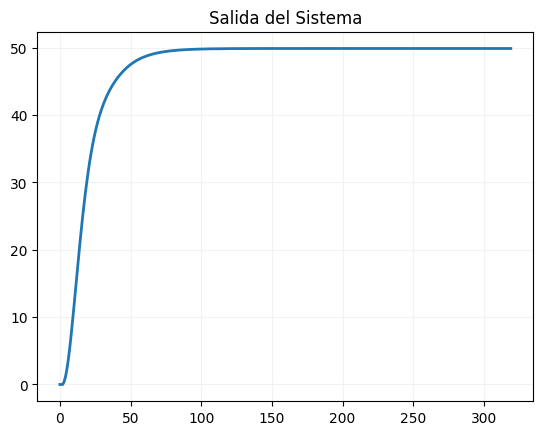

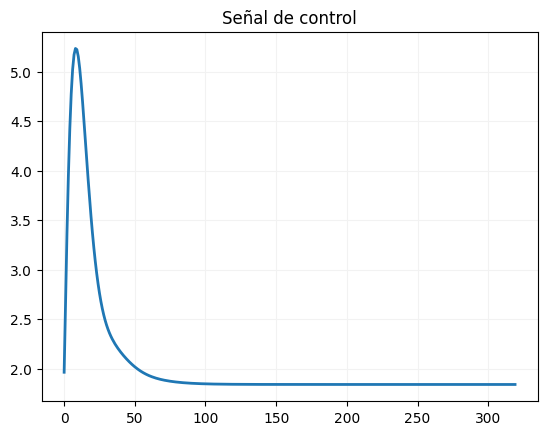

In [47]:
best_individual = population[0]
gene, fitness = best_individual
print("Mejor cromosoma:", gene)

DC = dibujacontrol()
DC.dibujar(gene[0],gene[1], gene[2])